# 03. Metropolis-Hastings and convergence diagnostics

## Business use

Any pricing, conversion, or cost model without a closed form is fit by MCMC. In production the sampler is NUTS inside PyMC. Metropolis-Hastings is the ancestor: same stationary distribution, same diagnostics, a cruder proposal. Coding it makes the diagnostics mean something.

## Intuition

You can evaluate the posterior up to a constant but not sample it directly. Take a random walk: always accept a more plausible point, and sometimes accept a worse one, in proportion to how much worse it is. After burn-in, time spent in a region matches its posterior mass.

## Math

Propose $\theta'$ from $q(\theta' \mid \theta)$ and accept with probability

$$
\min\left(1,\ \frac{p(\theta' \mid y)\, q(\theta \mid \theta')}{p(\theta \mid y)\, q(\theta' \mid \theta)}\right).
$$

Only the unnormalised posterior is required: the evidence $p(y)$ cancels. A symmetric random-walk proposal makes the $q$ ratio 1. The rule satisfies detailed balance, so the posterior is the chain's stationary distribution.

Rank-normalised split R-hat compares between-chain and within-chain variance (Vehtari et al., 2021). ESS divides the draw count by an autocorrelation penalty. ArviZ reports both.

The worked example is logistic conversion: $y = 1$ if a session converts, discount in $[0, 0.4]$,

$$
\mathrm{logit}\, p = a + b \cdot \mathrm{discount},
$$

with priors $a \sim \mathrm{Normal}(0, 2.5)$ and $b \sim \mathrm{Normal}(0, 5)$. Truth is $a = -2.5$, $b = 4$.


## Step 1. Log posterior


In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pymc as pm
from IPython.display import display
from scipy.stats import rankdata

rng = np.random.default_rng(7)
n_sessions = 2000
discount = rng.uniform(0, 0.4, n_sessions)
true_a, true_b = -2.5, 4.0
probability = 1 / (1 + np.exp(-(true_a + true_b * discount)))
y = rng.binomial(1, probability)
print("sessions:", n_sessions, "conversion rate:", round(float(y.mean()), 3))


def log_post(theta: np.ndarray) -> float:
    a, b = theta
    eta = a + b * discount
    loglik = np.sum(y * eta - np.logaddexp(0, eta))
    logprior = -0.5 * (a / 2.5) ** 2 - 0.5 * (b / 5) ** 2
    return float(loglik + logprior)

sessions: 2000 conversion rate: 0.167


## Step 2. Random-walk Metropolis

Accept in log space: $\log u < \log p(\theta') - \log p(\theta)$. On rejection, repeat the current state. Dropping rejected proposals biases the sample. Four chains, dispersed starts, 6,000 iterations, 1,000 discarded as burn-in.


In [2]:
def metropolis(n_iter: int, step: float, start: tuple[float, float], seed: int):
    random = np.random.default_rng(seed)
    theta = np.array(start, dtype=float)
    logp = log_post(theta)
    draws = np.empty((n_iter, 2))
    accepted = 0
    for t in range(n_iter):
        proposal = theta + random.normal(0, step, size=2)
        logp_proposal = log_post(proposal)
        if np.log(random.uniform()) < logp_proposal - logp:
            theta = proposal
            logp = logp_proposal
            accepted += 1
        draws[t] = theta
    return draws, accepted / n_iter


starts = [(-5.0, 0.0), (0.0, 8.0), (-1.0, 2.0), (-4.0, 6.0)]
burn = 1000
records = []
for step in (0.005, 0.15, 2.0):
    chains = []
    accept = []
    for chain_id, start in enumerate(starts):
        draws, rate = metropolis(6000, step, start, seed=chain_id)
        chains.append(draws[burn:])
        accept.append(rate)
    stacked = np.stack(chains)
    idata = az.from_dict({"posterior": {"a": stacked[..., 0], "b": stacked[..., 1]}})
    summary = az.summary(idata)
    records.append({"step": step, "accept": np.array(accept), "stacked": stacked, "summary": summary})
    print(f"\n=== step={step}  acceptance per chain={np.round(accept, 2)}")
    print(summary.to_string())

print("true a, b:", true_a, true_b)


=== step=0.005  acceptance per chain=[0.88 0.87 0.94 0.95]
   mean   sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
a  -2.5  0.6     -3.3     -1.7        5        8  1.90      0.28   0.055
b     4  2.6     0.86      7.1        4        4  3.65       1.3    0.25



=== step=0.15  acceptance per chain=[0.41 0.42 0.42 0.43]
    mean    sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
a  -2.55  0.14     -2.8     -2.3      155      248  1.02     0.012  0.0056
b   4.32  0.56      3.5      5.2      127      176  1.02     0.049   0.026



=== step=2.0  acceptance per chain=[0.02 0.01 0.02 0.01]
    mean    sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
a  -2.55  0.13     -2.8     -2.3      168      173  1.03      0.01  0.0082
b   4.31   0.5      3.5      5.2      177      192  1.03     0.037   0.031
true a, b: -2.5 4.0


## Step 3. Match the proposal to the posterior

$a$ and $b$ are strongly correlated: a higher intercept and a lower slope can explain the same conversions. An isotropic step cannot move along that ridge, so acceptance can look healthy while ESS stays poor.

Pilot the chain, estimate the covariance, and propose with the Roberts-Gelman-Gilks scale $(2.38)^2 / d$ times that covariance. $d = 2$ here.


In [3]:
pilot, _ = metropolis(6000, 0.15, (-1.0, 2.0), seed=99)
pilot_draws = pilot[burn:]
covariance = np.cov(pilot_draws.T)
correlation = covariance[0, 1] / np.sqrt(covariance[0, 0] * covariance[1, 1])
print("posterior corr(a, b) from pilot:", round(float(correlation), 2))
scale = (2.38**2 / 2) * covariance
chol = np.linalg.cholesky(scale + 1e-10 * np.eye(2))


def metropolis_cov(n_iter: int, chol_factor: np.ndarray, start: tuple[float, float], seed: int):
    random = np.random.default_rng(seed)
    theta = np.array(start, dtype=float)
    logp = log_post(theta)
    draws = np.empty((n_iter, 2))
    accepted = 0
    for t in range(n_iter):
        proposal = theta + chol_factor @ random.normal(size=2)
        logp_proposal = log_post(proposal)
        if np.log(random.uniform()) < logp_proposal - logp:
            theta = proposal
            logp = logp_proposal
            accepted += 1
        draws[t] = theta
    return draws, accepted / n_iter


adapted_chains = []
adapted_accept = []
for chain_id, start in enumerate(starts):
    draws, rate = metropolis_cov(6000, chol, start, seed=chain_id)
    adapted_chains.append(draws[burn:])
    adapted_accept.append(rate)
adapted = np.stack(adapted_chains)
adapted_idata = az.from_dict({"posterior": {"a": adapted[..., 0], "b": adapted[..., 1]}})
adapted_summary = az.summary(adapted_idata)
print("acceptance:", np.round(adapted_accept, 2))
print(adapted_summary.to_string())
assert float(adapted_summary["r_hat"].astype(float).max()) < 1.01
assert float(adapted_summary["ess_bulk"].astype(float).min()) > 400

posterior corr(a, b) from pilot: -0.92


acceptance: [0.34 0.35 0.34 0.35]
     mean     sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
a  -2.545  0.145     -2.8     -2.3     2805     3263  1.00    0.0027  0.0018
b    4.29   0.56      3.4      5.2     2907     3256  1.00      0.01  0.0071


## Step 4. Same model with NUTS

PyMC's default sampler is the production reference. The posterior means should agree with the adapted random walk. NUTS uses gradient information, so it needs fewer draws for the same ESS, and it reports divergences rather than an acceptance rate.


In [4]:
with pm.Model():
    a = pm.Normal("a", 0, 2.5)
    b = pm.Normal("b", 0, 5)
    pm.Bernoulli("y", logit_p=a + b * discount, observed=y)
    nuts = pm.sample(1000, tune=1000, chains=4, cores=2, random_seed=1, progressbar=False)
nuts_summary = az.summary(nuts)
print("NUTS divergences:", int(np.asarray(nuts.sample_stats["diverging"]).sum()))
print(nuts_summary.to_string())

slope = adapted[..., 1].ravel()
intercept = adapted[..., 0].ravel()
p_discount = 1 / (1 + np.exp(-(intercept + 0.2 * slope)))
p_base = 1 / (1 + np.exp(-intercept))
print("P(b>0) =", round(float(np.mean(slope > 0)), 3))
print("median conversion lift from a 20% discount:", round(float(np.median(p_discount - p_base)), 3))

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 2 jobs)


NUTS: [a, b]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 3 seconds.


NUTS divergences: 0
     mean    sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
a  -2.546  0.14     -2.8     -2.3     1026     1128  1.00    0.0044   0.003
b     4.3  0.53      3.4      5.2     1073     1085  1.00     0.016   0.011
P(b>0) = 1.0
median conversion lift from a 20% discount: 0.083


## Step 5. Pictures of mixing


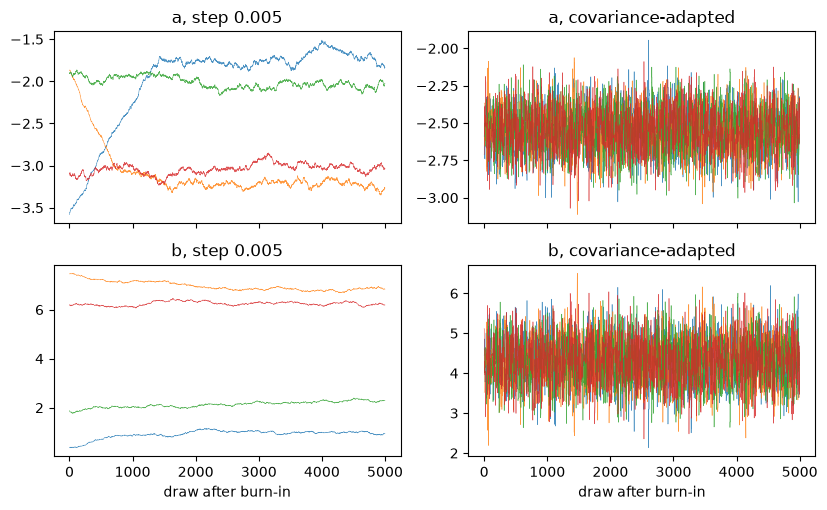

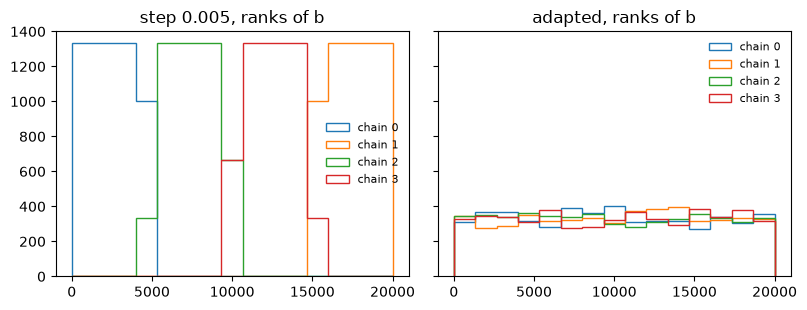

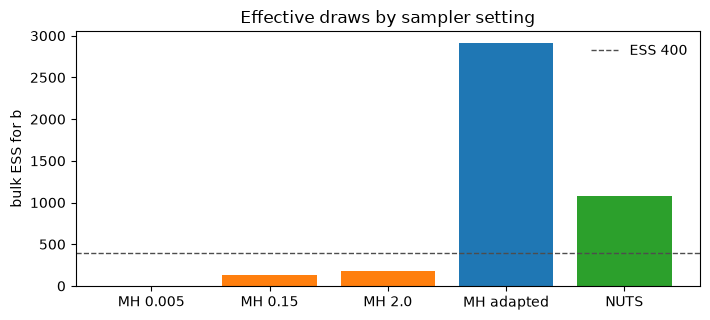

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(8.4, 5.2), sharex="col")
for column, (label, stacked) in enumerate(
    (("step 0.005", records[0]["stacked"]), ("covariance-adapted", adapted))
):
    for row, (name, series) in enumerate((("a", stacked[..., 0]), ("b", stacked[..., 1]))):
        ax = axes[row, column]
        for chain in series:
            ax.plot(chain, lw=0.4, alpha=0.8)
        ax.set_title(f"{name}, {label}")
axes[1, 0].set_xlabel("draw after burn-in")
axes[1, 1].set_xlabel("draw after burn-in")
fig.tight_layout()
display(fig)
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.2), sharey=True)
for ax, label, series in (
    (axes[0], "step 0.005, ranks of b", records[0]["stacked"][..., 1]),
    (axes[1], "adapted, ranks of b", adapted[..., 1]),
):
    ranks = rankdata(series.ravel()).reshape(series.shape)
    bins = np.linspace(0, series.size, 16)
    for chain_id, row in enumerate(ranks):
        ax.hist(row, bins=bins, histtype="step", label=f"chain {chain_id}")
    ax.set_title(label)
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

ess = [float(rec["summary"].loc["b", "ess_bulk"]) for rec in records]
ess.append(float(adapted_summary.loc["b", "ess_bulk"]))
ess.append(float(nuts_summary.loc["b", "ess_bulk"]))
labels = ["MH 0.005", "MH 0.15", "MH 2.0", "MH adapted", "NUTS"]
fig, ax = plt.subplots(figsize=(7.2, 3.3))
ax.bar(labels, ess, color=["C3", "C1", "C1", "C0", "C2"])
ax.axhline(400, color="0.3", ls="--", lw=1, label="ESS 400")
ax.set_ylabel("bulk ESS for b")
ax.set_title("Effective draws by sampler setting")
ax.legend(frameon=False)
fig.tight_layout()
display(fig)
plt.close(fig)

## How to read the diagnostics

| Check | Threshold | What failure means |
|---|---|---|
| R-hat (rank-normalised, split) | 1.00, below 1.01 | Chains disagree. Run longer or reparameterise. |
| ESS bulk and tail | Above about 400 in total | Too few effective draws for a stable mean or tail interval. |
| Acceptance (MH) | About 0.20 to 0.45 | Very high: steps are tiny and the chain drifts. Very low: the chain is stuck. |
| Divergences (NUTS only) | 0 | Curved regions such as funnels were not explored. The posterior can be biased. |
| Trace | Overlapping fuzzy caterpillars | Snakes: tiny steps. Flat stretches: rejections. Separate bands: different modes. |
| Rank plot | Roughly uniform histograms per chain | A hump means one chain over-visits a region. |
| E-BFMI (NUTS) | Above about 0.3 | Momentum resampling is too weak. Often a hierarchy problem. |

The lesson in the table: a step of 0.15 can accept about 40% of proposals and still leave R-hat above 1.01 with only a hundred effective draws, because $a$ and $b$ are correlated near -0.9. Acceptance is not mixing. Matching the proposal to that ridge pushes ESS into the thousands and R-hat to 1.00. A tiny step (0.005) accepts almost everything and barely moves. A huge step (2) accepts almost nothing; you do record the current state on each rejection, but the chain stays put for long stretches.

NUTS on the same posterior should land on the same means. It is the default we ship. The hand-written sampler is how we know what the diagnostics are checking.

## Pitfalls

- An asymmetric proposal (a log-normal step on a positive parameter) needs the Hastings correction $q(\theta \mid \theta') / q(\theta' \mid \theta)$.
- Proposing a negative standard deviation: sample $\log \sigma$ and add the Jacobian.
- One chain cannot support R-hat.
- Thinning does not fix autocorrelation. Run longer or improve the proposal.
- Judging the chain by acceptance rate alone.
- Forgetting to record the current state on rejection.


## How to explain this to a CTO


In [6]:
print(
    "The sampler is a simulation of what we believe about the parameters. "
    "The diagnostics tell us whether we ran it long enough that rerunning would not change the decision. "
    "We do not publish a model that fails them, and that check runs in the training pipeline."
)
lift_points = float(np.median(p_discount - p_base)) * 100
print(
    f"Here the discount slope is positive with probability {float(np.mean(slope > 0)):.0%}. "
    f"Moving the discount from 0 to 20% changes conversion by about {lift_points:+.1f} "
    "percentage points at the median of the posterior. "
    "That is the number to discuss, not the trace plot."
)

The sampler is a simulation of what we believe about the parameters. The diagnostics tell us whether we ran it long enough that rerunning would not change the decision. We do not publish a model that fails them, and that check runs in the training pipeline.
Here the discount slope is positive with probability 100%. Moving the discount from 0 to 20% changes conversion by about +8.3 percentage points at the median of the posterior. That is the number to discuss, not the trace plot.


## Check yourself

**Why does Metropolis-Hastings work?**
The acceptance probability satisfies detailed balance, so the posterior is stationary for the chain. After burn-in, the draws are correlated samples from it. You never need $p(y)$, only ratios of the unnormalised posterior.

**What is a divergence?**
A NUTS trajectory whose integrator exploded, usually in a region of high curvature. The chain avoids that region, so the fit can be biased. Non-centred hierarchies and a higher target acceptance are the usual fixes. See the thin-data cell in notebook 01.
